# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

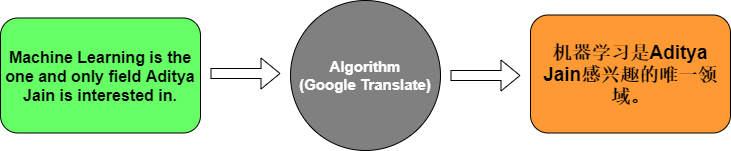

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [ ]:
#!pip install tensorflow

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [ ]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [ ]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [ ]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step - accuracy: 0.1429 - loss: 2.4846 - val_accuracy: 0.0000e+00 - val_loss: 2.4882
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 381ms/step - accuracy: 0.5714 - loss: 2.4762 - val_accuracy: 0.0000e+00 - val_loss: 2.4898
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - accuracy: 0.5714 - loss: 2.4675 - val_accuracy: 0.0000e+00 - val_loss: 2.4915
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.5714 - loss: 2.4584 - val_accuracy: 0.0000e+00 - val_loss: 2.4935
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.5714 - loss: 2.4483 - val_accuracy: 0.0000e+00 - val_loss: 2.4958
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 346ms/step - accuracy: 0.5714 - loss: 2.4370 - val_accuracy: 0.0000e+00 - val_loss: 2.4983
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.5714 - loss: 2.4240 - val_accuracy: 0.0000e+00 - val_loss: 2.5013
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.5714 - loss: 2.4089 - val_acc

In [ ]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 425ms/step
Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


1. What does the Embedding layer do to a word index?
It turns each integer word index into a dense vector of numbers (here, 64 values). The vectors are learned during training, so words with similar meanings or uses have similar vectors. This gives the model far more information than a bare number like 7.

2. What is the role of the Encoder LSTM?
It reads the embedded English sentence one word at a time and compresses its meaning into one fixed-size vector, the final hidden state. RepeatVector then copies this “context vector” once for each French output timestep.

3. What does the Decoder LSTM do?
It takes the repeated context vector and generates a sequence of hidden states, one per output position (return_sequences=True). Each hidden state represents what the French word at that position should be, given the meaning of the English sentence.

4. Why do we use softmax in the final layer?
Softmax converts the raw scores for each French word in the vocabulary into probabilities that sum to 1 at each timestep. This lets us train with sparse_categorical_crossentropy and pick the most likely word with argmax during translation.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [1]:
import re
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

df = pd.read_csv("eng_-french.csv")
df.columns = ["english", "french"]   # original: 'English words/sentences', 'French words/sentences'
print(df.shape)
df.head()

(175621, 2)


,english,french
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !


In [2]:
def clean(text):
    text = str(text).lower().strip()
    text = re.sub(r"[^a-zàâäçéèêëîïôöûùüÿœæ' ]", " ", text)  # keep letters, French accents, apostrophes
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["english"] = df["english"].apply(clean)
df["french"]  = df["french"].apply(clean)
df = df.dropna().drop_duplicates()

# Keep short sentences so training fits in memory and runs fast
df = df[(df["english"].str.split().str.len() <= 8) & (df["french"].str.split().str.len() <= 10)]
df = df.sample(n=min(30000, len(df)), random_state=42).reset_index(drop=True)
print("Samples used:", len(df))

Samples used: 30000


In [3]:
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(df["english"])
eng_sequences = tokenizer_eng.texts_to_sequences(df["english"])

tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(df["french"])
frn_sequences = tokenizer_frn.texts_to_sequences(df["french"])

eng_vocab = len(tokenizer_eng.word_index) + 1
frn_vocab = len(tokenizer_frn.word_index) + 1

eng_padded = pad_sequences(eng_sequences, padding="post")
frn_padded = pad_sequences(frn_sequences, padding="post")
eng_len, frn_len = eng_padded.shape[1], frn_padded.shape[1]

print("English vocab:", eng_vocab, "| max len:", eng_len)
print("French vocab:", frn_vocab, "| max len:", frn_len)

English vocab: 6943 | max len: 8
French vocab: 11628 | max len: 10


In [4]:
eng_train, eng_test, frn_train, frn_test = train_test_split(
    eng_padded, frn_padded, test_size=0.2, random_state=42)

In [5]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(eng_len,)),
    tf.keras.layers.Embedding(input_dim=eng_vocab, output_dim=256, mask_zero=True),
    tf.keras.layers.LSTM(256),                                   # Encoder
    tf.keras.layers.RepeatVector(frn_len),
    tf.keras.layers.LSTM(256, return_sequences=True),            # Decoder
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(frn_vocab, activation="softmax"))
])

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.003),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 8, 256)         │     1,777,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 256)            │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 10, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 10, 256)        │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 10, 11628)      │     2,988,396 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,816,428 (22.19 MB)

 Trainable params: 5,816,428 (22.19 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = model.fit(
    eng_train, np.expand_dims(frn_train, -1),
    epochs=30, batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop])

Epoch 1/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 22s 71ms/step - accuracy: 0.4261 - loss: 4.8681 - val_accuracy: 0.4471 - val_loss: 4.5488
Epoch 2/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 22s 72ms/step - accuracy: 0.4474 - loss: 4.4366 - val_accuracy: 0.4497 - val_loss: 4.4180
Epoch 3/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 22s 72ms/step - accuracy: 0.4507 - loss: 4.3128 - val_accuracy: 0.4529 - val_loss: 4.3284
Epoch 4/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 22s 73ms/step - accuracy: 0.4574 - loss: 4.2074 - val_accuracy: 0.4633 - val_loss: 4.2249
Epoch 5/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 24s 78ms/step - accuracy: 0.4685 - loss: 4.0749 - val_accuracy: 0.4737 - val_loss: 4.0665
Epoch 6/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 23s 76ms/step - accuracy: 0.4840 - loss: 3.6942 - val_accuracy: 0.4878 - val_loss: 3.6699
Epoch 7/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 23s 76ms/step - accuracy: 0.4955 - loss: 3.4011 - val_accuracy: 0.4941 - val_loss: 3.5767
Epoch 8/30
300/300 ━━━━━━━━━━━━━━━━━━━━ 23s 76ms/step - accuracy: 0.5067 - loss: 3.2194 - 

In [7]:
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.5435 - loss: 3.1259
Test Loss: 3.1259
Test Accuracy: 0.5435


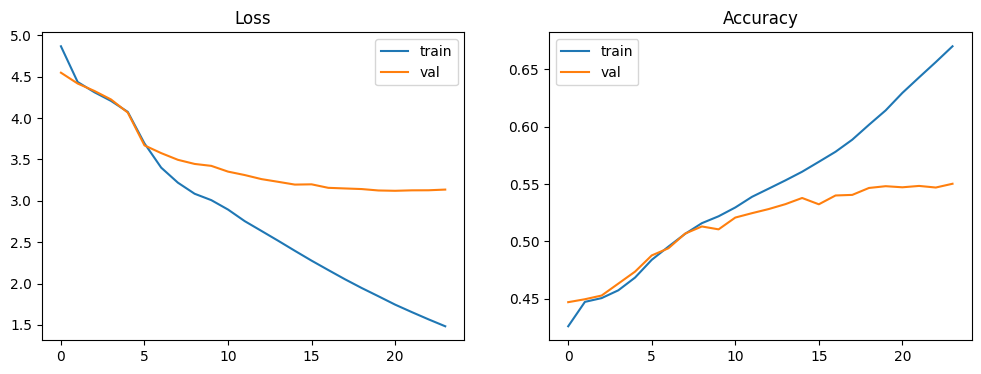

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.title("Loss"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.title("Accuracy"); plt.legend()
plt.show()

In [9]:
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([clean(sentence)])
    padded_sequence = pad_sequences(sequence, maxlen=eng_len, padding="post")
    predicted_sequence = model.predict(padded_sequence, verbose=0)
    translated_sequence = np.argmax(predicted_sequence, axis=-1)
    return frn_tokenizer.sequences_to_texts(translated_sequence)[0]

# Compare with real test examples
for i in range(5):
    eng = tokenizer_eng.sequences_to_texts([eng_test[i]])[0]
    ref = tokenizer_frn.sequences_to_texts([frn_test[i]])[0]
    pred = translate_sentence(eng, model, tokenizer_eng, tokenizer_frn)
    print(f"EN: {eng}\nREF: {ref}\nPRED: {pred}\n")

# E-commerce style sentences
for s in ["this product is very good", "i like this shirt", "the price is too high", "where is my order"]:
    print(f"{s}  ->  {translate_sentence(s, model, tokenizer_eng, tokenizer_frn)}")

EN: what are you so angry about
REF: qu'est ce qui te met tant en colère
PRED: qu'est ce tu vous de

EN: a car hit tom
REF: tom a été heurté par une voiture
PRED: la vieil la signée à tom

EN: that will put you in danger
REF: ça te mettra en danger
PRED: c'est vous heure tu demain

EN: will that be all
REF: ce sera tout
PRED: tout il il

EN: tom can ski just as well as mary
REF: tom peut skier tout aussi bien que mary
PRED: tom sait peut que que que mary mary

this product is very good  ->  ce ci est trop lourd
i like this shirt  ->  j'aime cette clé
the price is too high  ->  le est est vraiment élevés
where is my order  ->  où est votre mon
